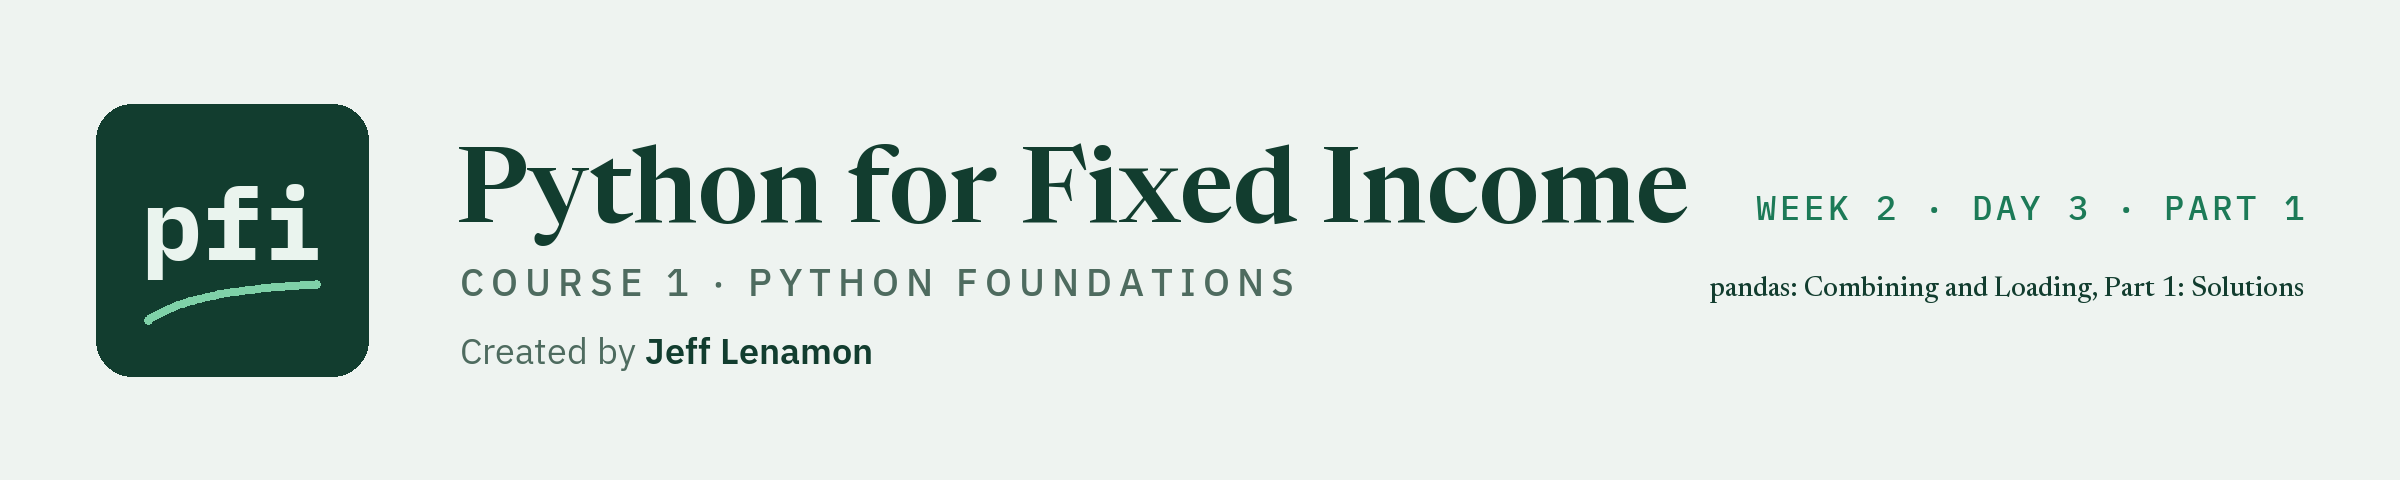

# pandas: Combining and Loading, Part 1: Solutions

Week 2, Day 3, Part 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day3/08_pandas_combining_and_loading_solutions.ipynb)

## Exercises

These are the worked answers to the exercises in the teaching notebook.

They use the holdings, the benchmark, and the rating scale; the issuers are invented.

Each answer is followed by the check cell from the teaching notebook.
Run the next cell first: it loads fresh copies of the three files and defines `check`.

In [1]:
import os

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text;
    # isinstance(expected, list) is True when expected is a list
    if getattr(answer, 'ndim', 0) > 0 and not isinstance(expected, list):
        # a whole column or table was stored where a single value is expected
        print(label + ': not yet. A single value is expected, and you have a column or a table.')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance;
        # abs() drops the sign, so this is the size of the gap between the two
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# fresh copies of three files. In Colab they are read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
benchmark = pd.read_csv(data_folder + 'benchmark.csv')
print(holdings.shape, ratings.shape, benchmark.shape)

(200, 19) (18, 4) (821, 19)


### Exercise 1

Q. Merge the benchmark with the rating scale. How many benchmark bonds are High Yield, and what is their total weight in the benchmark, in percent, rounded to one decimal place? Store the answers in **ex1_count** and **ex1_weight**.

In [2]:
# every benchmark bond has a rating, so the rating is the key
benchmark_rated = pd.merge(benchmark, ratings, on='rating')
# the row count should not change
print('Rows:', benchmark.shape[0], 'in,', benchmark_rated.shape[0], 'out')

# True where the bond is high yield
is_hy = benchmark_rated['grade'] == 'High Yield'

ex1_count = is_hy.sum()
ex1_weight = round(benchmark_rated.loc[is_hy, 'weight_pct'].sum(), 1)

print('High yield bonds in the benchmark:', ex1_count)
print('Their weight:', ex1_weight)

Rows: 821 in, 821 out
High yield bonds in the benchmark: 281
Their weight: 34.4


821 rows in and 821 out, so the merge kept every bond.
281 of them are High Yield, and they carry 34.4 percent of the benchmark's weight.

In [3]:
check('Exercise 1 count', ex1_count, 281)
check('Exercise 1 weight', ex1_weight, 34.4)

Exercise 1 count: correct
Exercise 1 weight: correct


### Exercise 2

Q. Merge the holdings with the rating scale, and total the face held in each rating bucket. How much face does the desk hold in the BBB bucket? Which three buckets have the most face, largest first? Store the answers in **ex2_bbb_face** and, as a list, in **ex2_top_buckets**.

In [4]:
# bring the bucket and the grade into the holdings
book = pd.merge(holdings, ratings, on='rating')

# face held, added up within each bucket
bucket_face = book.groupby('bucket')['par_held'].sum()
ex2_bbb_face = bucket_face.loc['BBB']
print('Face in the BBB bucket:', ex2_bbb_face)

# sort the grouped result, keep the top three, and take the bucket names from the index
top_three = bucket_face.sort_values(ascending=False).head(3)
ex2_top_buckets = top_three.index.tolist()
print(top_three)

Face in the BBB bucket: 151750000
bucket
BBB    151750000
A      147500000
BB     111750000
Name: par_held, dtype: int64


151,750,000 of face in the BBB bucket, which is the largest.
The A bucket follows with 147,500,000, then BB with 111,750,000.

In [5]:
check('Exercise 2 BBB face', ex2_bbb_face, 151750000)
check('Exercise 2 top buckets', ex2_top_buckets, ['BBB', 'A', 'BB'])

Exercise 2 BBB face: correct
Exercise 2 top buckets: correct


### Exercise 3

Q. Mark each benchmark bond with the face the desk holds in it, with a left merge on the CUSIP. Among the benchmark's Energy bonds, how many does the desk hold, and what is their benchmark weight, in percent, rounded to two decimal places? Store the answers in **ex3_count** and **ex3_weight**.

In [6]:
# the benchmark is the left table, so all of its bonds are kept
compared = pd.merge(benchmark, holdings[['cusip', 'par_held']], on='cusip', how='left')
# the row count should not change
print('Rows:', benchmark.shape[0], 'in,', compared.shape[0], 'out')

# held by the desk, and in the Energy sector
held_energy = compared['par_held'].notna() & (compared['sector'] == 'Energy')

ex3_count = held_energy.sum()
ex3_weight = round(compared.loc[held_energy, 'weight_pct'].sum(), 2)

print('Energy bonds held:', ex3_count)
print('Their benchmark weight:', ex3_weight)

Rows: 821 in, 821 out
Energy bonds held: 17
Their benchmark weight: 2.29


821 rows in and 821 out.
The desk holds 17 of the benchmark's Energy bonds, and they carry 2.29 percent of its weight.

In [7]:
check('Exercise 3 count', ex3_count, 17)
check('Exercise 3 weight', ex3_weight, 2.29)

Exercise 3 count: correct
Exercise 3 weight: correct


### Exercise 4

Q. Split the holdings into the bonds priced below 100 and the bonds priced at 100 or above. Store the number of bonds below 100 in **ex4_below**. Stack the two tables with `pd.concat()`, numbering the rows again from 0, and store the result in **ex4_stacked**. Then store its number of rows in **ex4_rows** and its total market value in **ex4_value**.

In [8]:
# the two parts
below = holdings[holdings['price'] < 100]
at_or_above = holdings[holdings['price'] >= 100]
ex4_below = below.shape[0]

# ignore_index=True numbers the stacked rows again from 0
ex4_stacked = pd.concat([below, at_or_above], ignore_index=True)

ex4_rows = ex4_stacked.shape[0]
ex4_value = ex4_stacked['market_value'].sum()

print('Below 100:', ex4_below)
print('Stacked rows:', ex4_rows)
print('Market value:', ex4_value)

Below 100: 113
Stacked rows: 200
Market value: 490819215.0


113 bonds are below 100, and the stack holds all 200.
The market value is 490,819,215, the total of the holdings, so nothing was lost or repeated.

In [9]:
check('Exercise 4 below 100', ex4_below, 113)
check('Exercise 4 rows', ex4_rows, 200)
check('Exercise 4 market value', ex4_value, 490819215.0)

Exercise 4 below 100: correct
Exercise 4 rows: correct
Exercise 4 market value: correct


### Exercise 5: AI check

You ask an AI assistant how many of the benchmark's Energy bonds the desk holds, and what benchmark weight they carry.
It gives you the code below.
It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What numbers do you expect? You worked both out yourself in Exercise 3. Then run the code. Does it agree with you?

The answers from Exercise 3 are 17 bonds and 2.29 percent.
The original code printed 96 bonds and 12.2 percent, with no error.
The bug was the key.
The code merged on the ticker, and an issuer can have several bonds on each side, so every benchmark bond of an issuer matched every bond the desk holds in that issuer.
A bond is identified by its CUSIP.
The row count gives it away: 821 rows went in and 1,372 came out.
This is the count check of section 8.3, and `validate='many_to_one'` would have stopped the merge.

In [10]:
# a bond is identified by its CUSIP, so the CUSIP is the key
ai_desk = holdings[['cusip', 'par_held']]
ai_compared = pd.merge(benchmark, ai_desk, on='cusip', how='left')

ai_held = ai_compared['par_held'].notna() & (ai_compared['sector'] == 'Energy')
ex5_count = ai_held.sum()
ex5_weight = round(ai_compared.loc[ai_held, 'weight_pct'].sum(), 2)

print(f'Energy bonds held: {ex5_count}')
print(f'Their benchmark weight: {ex5_weight}')

Energy bonds held: 17
Their benchmark weight: 2.29


In [11]:
check('Exercise 5 count', ex5_count, 17)
check('Exercise 5 weight', ex5_weight, 2.29)

Exercise 5 count: correct
Exercise 5 weight: correct
